ФЕДЕРАЛЬНОЕ ГОСУДАРСТВЕННОЕ АВТОНОМНОЕ ОБРАЗОВАТЕЛЬНОЕ УЧРЕЖДЕНИЕ
ВЫСШЕГО ОБРАЗОВАНИЯ
«НАЦИОНАЛЬНЫЙ ИССЛЕДОВАТЕЛЬСКИЙ УНИВЕРСИТЕТ
«ВЫСШАЯ ШКОЛА ЭКОНОМИКИ»

Факультет географии и геоинформационных технологий

Образовательная программа «География глобальных изменений и геоинформационные технологии»

*Дисциплина "Python для анализа данных"*

Проектная работа
**"Исследование структуры и динамики налоговых поступлений в России"**

Выполнил: студент 2 курса группы БГЕО252
*Султанов Самат*

Москва, 2026



## ВВЕДЕНИЕ

**Налоговые поступления** - это один из основных источников дохода государства. Интерес к этой теме подогрет новостями о повышении налоговых ставок. Такой постепенный рост является результатом налоговой политики. Цель этого проекта состоит в том, чтобы проанализировать, насколько сильным оказался рост в России за период с 2006 по 2025 год.

Для этого был использован датасет от ФНС России - достаточно объемная **[таблица](https://search.nsedc.ru/?q=налоговые+поступления&sources=Репозиторий+НЦСЭД)** (*без ДНР, ЛНР, Запорожской и Херсонской областей*). В ней содержатся значения налоговых поступлений для страны в целом, федеральных округов и регионов. В формате .xlsx или .csv практически невозможно понять, что отражают эти числа, и поэтому задача проекта - визуализировать данные максимально подробно и ясно, используя модули в Jupiter Notebook.

Для начала нужно открыть нашу таблицу, и импортировать необходимые для дальнейшей работы библиотеки.

In [9]:
!pip install xlrd openpyxl

Эта строчка необходима, чтобы читать файлы из Excel. Далее нужно убрать лишние строки (1, 2, и с 4 по 30234 - они содержат информацию по месяцам, а нам нужно за год), и попытаться открыть таблицу. Для примера откроем первые 5 строк таблицы.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

rows_to_skip = [0, 1]
for i_skip in range(3, 30234, 1):
    rows_to_skip.append(i_skip)   #задаем переменную со списком строк, которые нужно пропустить

table = pd.read_excel('taxes_rus.xls', sheet_name='Данные', skiprows=rows_to_skip)
table.head()   #с помощью pandas открываем только нужные нам строки с листа "Данные". Операция .head() показывает первые 5 строк

,Единица измерения,Период,Регионы,Справочник поступлений налоговых платежей по основным видам экономической деятельности,2006,2007,2008,2009,2010,2011,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
0,384 тысяча рублей,1558883 значение показателя за год,643 001. РОССИЙСКАЯ ФЕДЕРАЦИЯ,"37.02.52 Водоснабжение, водоотведение,организа...",NaN,NaN,NaN,NaN,NaN,NaN,...,84301874.0,103303429.0,118649490.0,130496367.0,161518991.0,175224050.0,192919559.0,204766547.0,241492069.0,NaN
1,384 тысяча рублей,1558883 значение показателя за год,643 001. РОССИЙСКАЯ ФЕДЕРАЦИЯ,37.02.35 Гостиницы и рестораны,23865246.0,34765580.0,53585059.0,45284866.0,55939493.0,65354287.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,384 тысяча рублей,1558883 значение показателя за год,643 001. РОССИЙСКАЯ ФЕДЕРАЦИЯ,37.02.39 Государственное управление и обеспече...,100568690.0,135233815.0,178526591.0,200441219.0,226854395.0,244795040.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,384 тысяча рублей,1558883 значение показателя за год,643 001. РОССИЙСКАЯ ФЕДЕРАЦИЯ,37.02.62 Государственное управление и обеспече...,NaN,NaN,NaN,NaN,NaN,NaN,...,415884361.0,439881692.0,469636480.0,532426373.0,582310353.0,572817040.0,741317342.0,765505432.0,955013782.0,NaN
4,384 тысяча рублей,1558883 значение показателя за год,643 001. РОССИЙСКАЯ ФЕДЕРАЦИЯ,37.02.61 Деятельность административная и сопут...,NaN,NaN,NaN,NaN,NaN,NaN,...,190552888.0,243107482.0,272300281.0,375369511.0,443471913.0,423752812.0,570992022.0,646101913.0,790550929.0,NaN


Как можно увидеть, "пробная" таблица отрисовалась хорошо, но в ней есть пропуски, и они чередуются. Такая шахматная доска объясняется тем, что в 2017 году был введен новый классификатор видов экономической деятельности ОКВЭД-2 (до этого был ОКВЭД-1). Многие отрасли были переименованы или укрупнены, и им присвоили новые коды.
*Например:* старый код `37.02.35` (Гостиницы и рестораны) перестал заполняться после 2016 года, а данные перешли в новый код `37.02.56` (Деятельность гостиниц и предприятий общественного питания).
Также в первые годы ведения статистики детализация по некоторым отраслям могла не выделятся в отдельную строку отчета.

**Как работать с такими данными?** Несмотря на различия в строках таблицы, широкий круг действий библиотек позволяет нам легко достать нужные данные, а суммарные значения за каждый год не теряются, ведь от изменения названия деятельности количество уплаченных налогов не изменится.




## 1. Кто сколько платит

Убедившись, что таблица открывается, приступим наконец к графикам. Первый график будет линейный, по регионам. Для этого надо из файла выбрать значения только по регионам, отбросив РФ и федеральные округа. Также нужно присоединить данные по упраздненным автономным округам к современным, как это сделали в 2005, 2007 и 2008 годах.

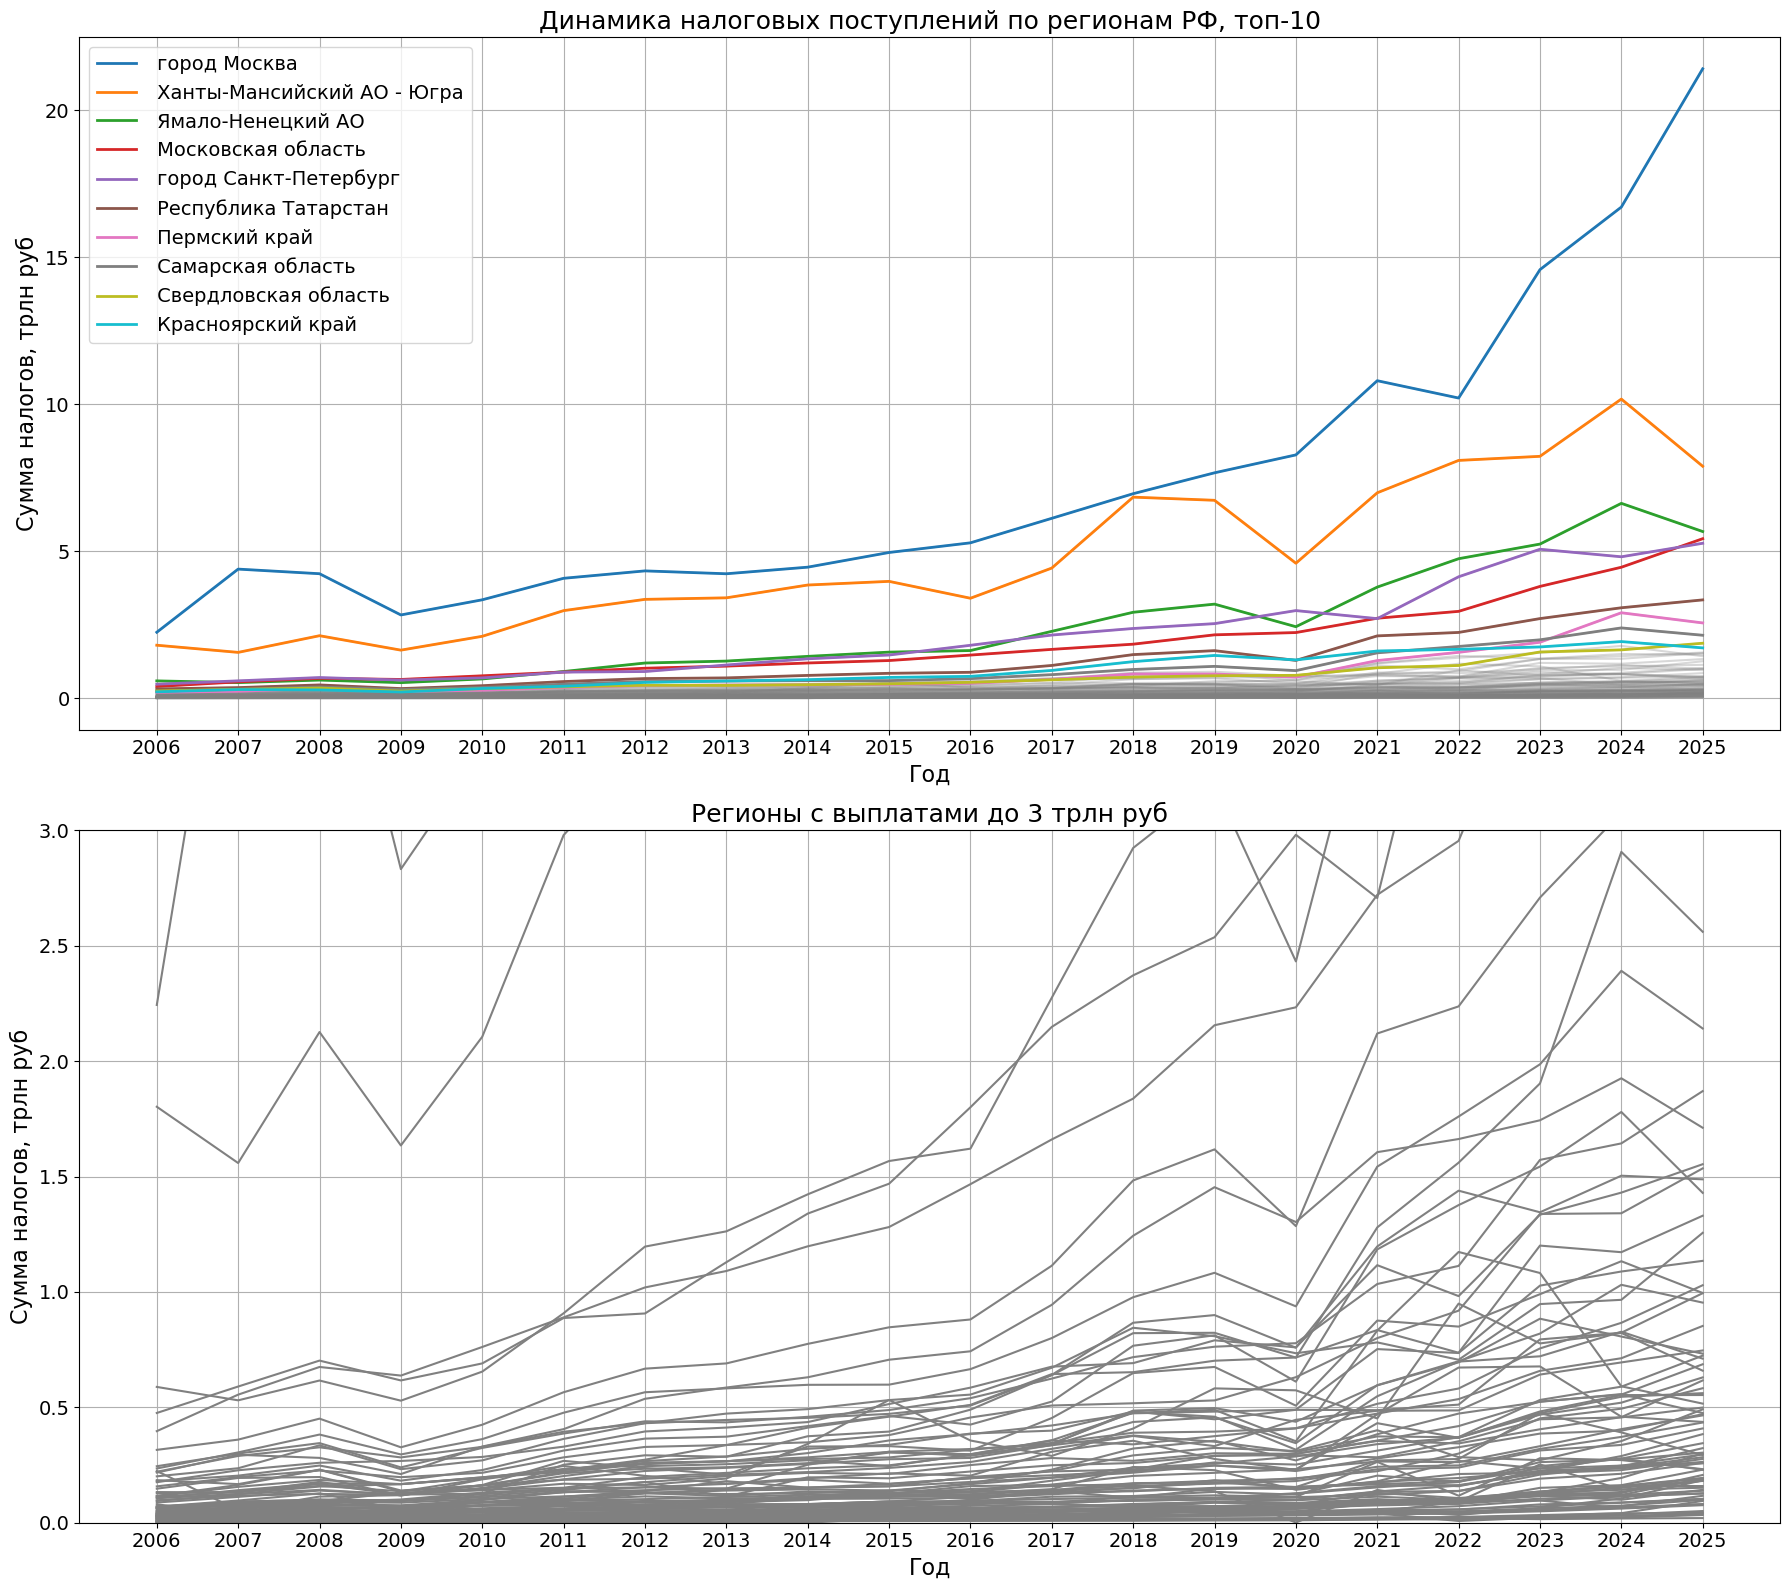

In [11]:
table_regions_raw = table[table['Регионы'] != '643 001. РОССИЙСКАЯ ФЕДЕРАЦИЯ'].copy()   #Берем в переменную все значения из столбца 'Регионы', не равные '643 001. РОССИЙСКАЯ ФЕДЕРАЦИЯ'
table_regions = table_regions_raw[table_regions_raw['Регионы'].str.contains('ОКРУГ') == False].copy()   #Берем значения, не содержащие 'ОКРУГ'
table_regions['Название_региона'] = table_regions['Регионы'].str.split('.').str[-1]
#Исключаем строки с данными по всей стране и по округам. Потом из названия регионов убираем цифры, оставляем только слова. Операция .copy() нужна для pandas, чтобы не возникало конфликтов

dict_rename = {' Коми-Пермяцкий АО': ' Пермский край', ' Усть-Ордынский Бурятский АО': ' Иркутская область',
    ' Таймырский АО': ' Красноярский край', ' Эвенкийский АО': ' Красноярский край',
    ' Корякский АО': ' Камчатский край', ' Агинский Бурятский АО': ' Забайкальский край'}
table_regions['Название_региона'] = table_regions['Название_региона'].replace(dict_rename)
#Упраздненные регионы присоединяем к существующим сейчас регионам

years_raw = []
for column in table_regions.columns:
    if str(column).isdigit():
        years_raw.append(column)
years = years_raw[:-1]   #Проверяем заголовки и добавляем только года в лист years_raw. Затем убираем 2026 год - этот столбец пустой.

regions_grouped_raw = table_regions.groupby('Название_региона')[years].sum()   #Суммируем все виды деятельности по данному региону, отдельно за каждый год
regions_grouped = regions_grouped_raw / 1000000000   #Делим получившуюся сумму на 1 млрд, чтобы не перегружать график

fig, ax = plt.subplots(2, 1, figsize=(18, 16))   #Задаем размер фигуры (графика) и ее параметры

for region_name in regions_grouped.index:
    ax[0].plot(years, regions_grouped.loc[region_name], color='gray', alpha=0.3)   #Показываем на графике все регионы полупрозрачным серым цветом

last_year = years[-1] 
top10 = regions_grouped[last_year].nlargest(10)   #Берем последний год, чтобы показать, какие регионы больше всего платят. В новую переменную добавляем 10 крупнейших

colors = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
for i in range(10):
    top_name = top10.index[i]
    ax[0].plot(years, regions_grouped.loc[top_name], label=top_name, color=colors[i], lw=2)   #Добавляем 10 крупнейших регионов на график, каждый - разным цветом. label позволит нам отобразить названия регионов в легенде
ax[0].set_title('Динамика налоговых поступлений по регионам РФ, топ-10', fontsize=18)
ax[0].set_xlabel('Год', fontsize=16)
ax[0].set_ylabel('Сумма налогов, трлн руб', fontsize=16)
ax[0].tick_params(labelsize=14)
ax[0].legend(loc='upper left', fontsize=14)
ax[0].grid()   #Делаем все по красоте - и первый график готов!

for region_name in regions_grouped.index:
    ax[1].plot(years, regions_grouped.loc[region_name], color='gray')
ax[1].set_ylim(0, 3) 
ax[1].set_title('Регионы с выплатами до 3 трлн руб', fontsize=18)
ax[1].set_xlabel('Год', fontsize=16)
ax[1].set_ylabel('Сумма налогов, трлн руб', fontsize=16)
ax[1].tick_params(labelsize=14)
ax[1].grid()   #Также красиво и читабельно рисуем второй график, пусть и без легенды (не поместится)
plt.tight_layout()   #Эта строка нужна, чтобы графики не наезжали друг на друга

Теперь у нас есть наглядный (или почти) график с регионами-лидерами, выплачивающими больше налогов, и остальными региоными, выплачивающими приблизительно одинаково. По результатам на 2025 год, больше 1 трлн рублей выплачивают 18 регионов, а более половины регионов отдают в казну менее 0,5 трлн рублей. **Огромный рост** за 20 лет показала **Москва**, *увеличив свои выплаты почти в 10 раз*. Отдельно от других на графике стоит и **ХМАО**, демонстрируя рост примерно *в 4 раза*.

Но в экономике есть такое понятие, как **инфляция**. Она "съедает" некоторую часть из этих денег, и если не учесть ее, проведенный анализ будет неполным. По данным сайта [calcus.ru](https://calcus.ru/inflyaciya?input=bW9udGgxPTEmeWVhcjE9MjAwNiZtb250aDI9MTImeWVhcjI9MjAyNQ==) за период времени с января 2006 по декабрь 2025 инфляция в России составила 354,07%, то есть цены выросли на 354,07%. Переводя это в отношение, получаем, что товар в 2025 стал стоить ***в 4,5407 раза*** дороже (*все верно, нужно обратить внимание на предлоги*).

Для того, чтобы узнать, как в действительности поменялась картина, напишем код, который будет брать значения 2006 и 2025 года для каждого региона, делить второе на первое и сравнивать, превышает ли получившееся значение рост цен. В зависимости от результата он выведет две строки: с регионами, увеличившими выплаты, и с уменьшившими. Также он выведет строку, сообщающую об увеличении или уменьшении суммы выплат, поступивших в бюджет с учетом инфляции.

In [3]:
year_2006 = years[0]
year_2025 = years[-1]
inflation = 4.5407
regions_plus = []
regions_minus = []   #Создаем пустые списки для вывода данных

for region in regions_grouped.index:
    value_2006 = regions_grouped.loc[region, year_2006]
    value_2025 = regions_grouped.loc[region, year_2025]   #Берем данные для регионов за 2006 и 2025 года 
    if value_2006 > 0:   #Эта проверка нужна, чтобы пропускать те регионы, которые не содержат значений в 2006 году.
                         #Таких быть не должно, но как мы видели, таблица имеет пустые ячейки, и нужно их пропускать
        growth = value_2025/value_2006
        if growth > inflation:
            regions_plus.append(region)   #Реальный рост больше инфляции - добро пожаловать в список "плюс"
        else:
            regions_minus.append(region)   #Реальный рост меньше инфляции - добро пожаловать в список "минус"
    else:
        if value_2025 > 0:
            regions_plus.append(region)   #Таких ячеек точно нет, это условие нужно чтобы закончить проверку и не повторять регионы при выводе

print("Регионы, выплатившие в 2025 БОЛЬШЕ, чем в 2006 с учетом инфляции:" + ','.join(regions_plus) + '.\n' + f'Всего: {len(regions_plus)} субъектов')
print("\nРегионы, выплатившие в 2025 МЕНЬШЕ, чем в 2006 с учетом инфляции:" + ','.join(regions_minus) + '.\n' +  f'Всего: {len(regions_minus)} субъектов')
#Это и есть наш основной вывод

total_2006, total_2025 = regions_grouped[year_2006].sum(), regions_grouped[year_2025].sum()
print("\nОбщий итог налоговых поступлений в бюджет:")
if total_2025 > (total_2006 * inflation):   #Узнаем, увеличился или уменьшился сбор налогов
    print("Сумма выплат в бюджет с учетом инфляции УВЕЛИЧИЛАСЬ")
else:
    print("Сумма выплат в бюджет с учетом инфляции УМЕНЬШИЛАСЬ")

Регионы, выплатившие в 2025 БОЛЬШЕ, чем в 2006 с учетом инфляции: Алтайский край, Амурская область, Архангельская область, Астраханская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Воронежская область, Еврейская автономная область, Ивановская область, Иркутская область, Кабардино-Балкарская Республика, Калининградская область, Калужская область, Камчатский край, Карачаево-Черкесская Республика, Кировская область, Костромская область, Краснодарский край, Красноярский край, Курганская область, Курская область, Ленинградская область, Магаданская область, Московская область, Ненецкий АО, Нижегородская область, Новгородская область, Новосибирская область, Омская область, Оренбургская область, Орловская область, Пензенская область, Пермский край, Приморский край, Псковская область, Республика Адыгея, Республика Алтай, Республика Башкортостан, Республика Бурятия, Республика Дагестан, Республика Ингушетия, Республика Калмыкия, Республика Карелия


Абсолютное большинство регионов показывает реальный рост выплат, что является для государства хорошим показателем. Увеличению суммы сборов способствовали рост экономики, цифровизация налоговой службы ("серые" доходы стали "белыми") и введение новых налогов. Тем не менее 8 регионов отдали меньше денежного эквивалента, чем в 2006, причем среди них ХМАО, занимающий второе место по абсолютному числу выплат. Чтобы узнать, почему некоторые регионы платят больше, а некоторые - меньше, нужно посмотреть структуру отраслей по стране и определить, какой вид деятельности сколько денег дает. И уже потом, сопоставив структуры экономик субъектов России, можно ответить на данный вопрос.




## 2. Где крутятся деньги

Необходимо построить график, похожий на предыдущий, взяв данные по **отраслям**. Это даст понять, какие виды деятельности приносят больше всего налогов. Для этого берем строки, содержащие значения по всей стране, и рисуем по ним три графика разного масштаба.

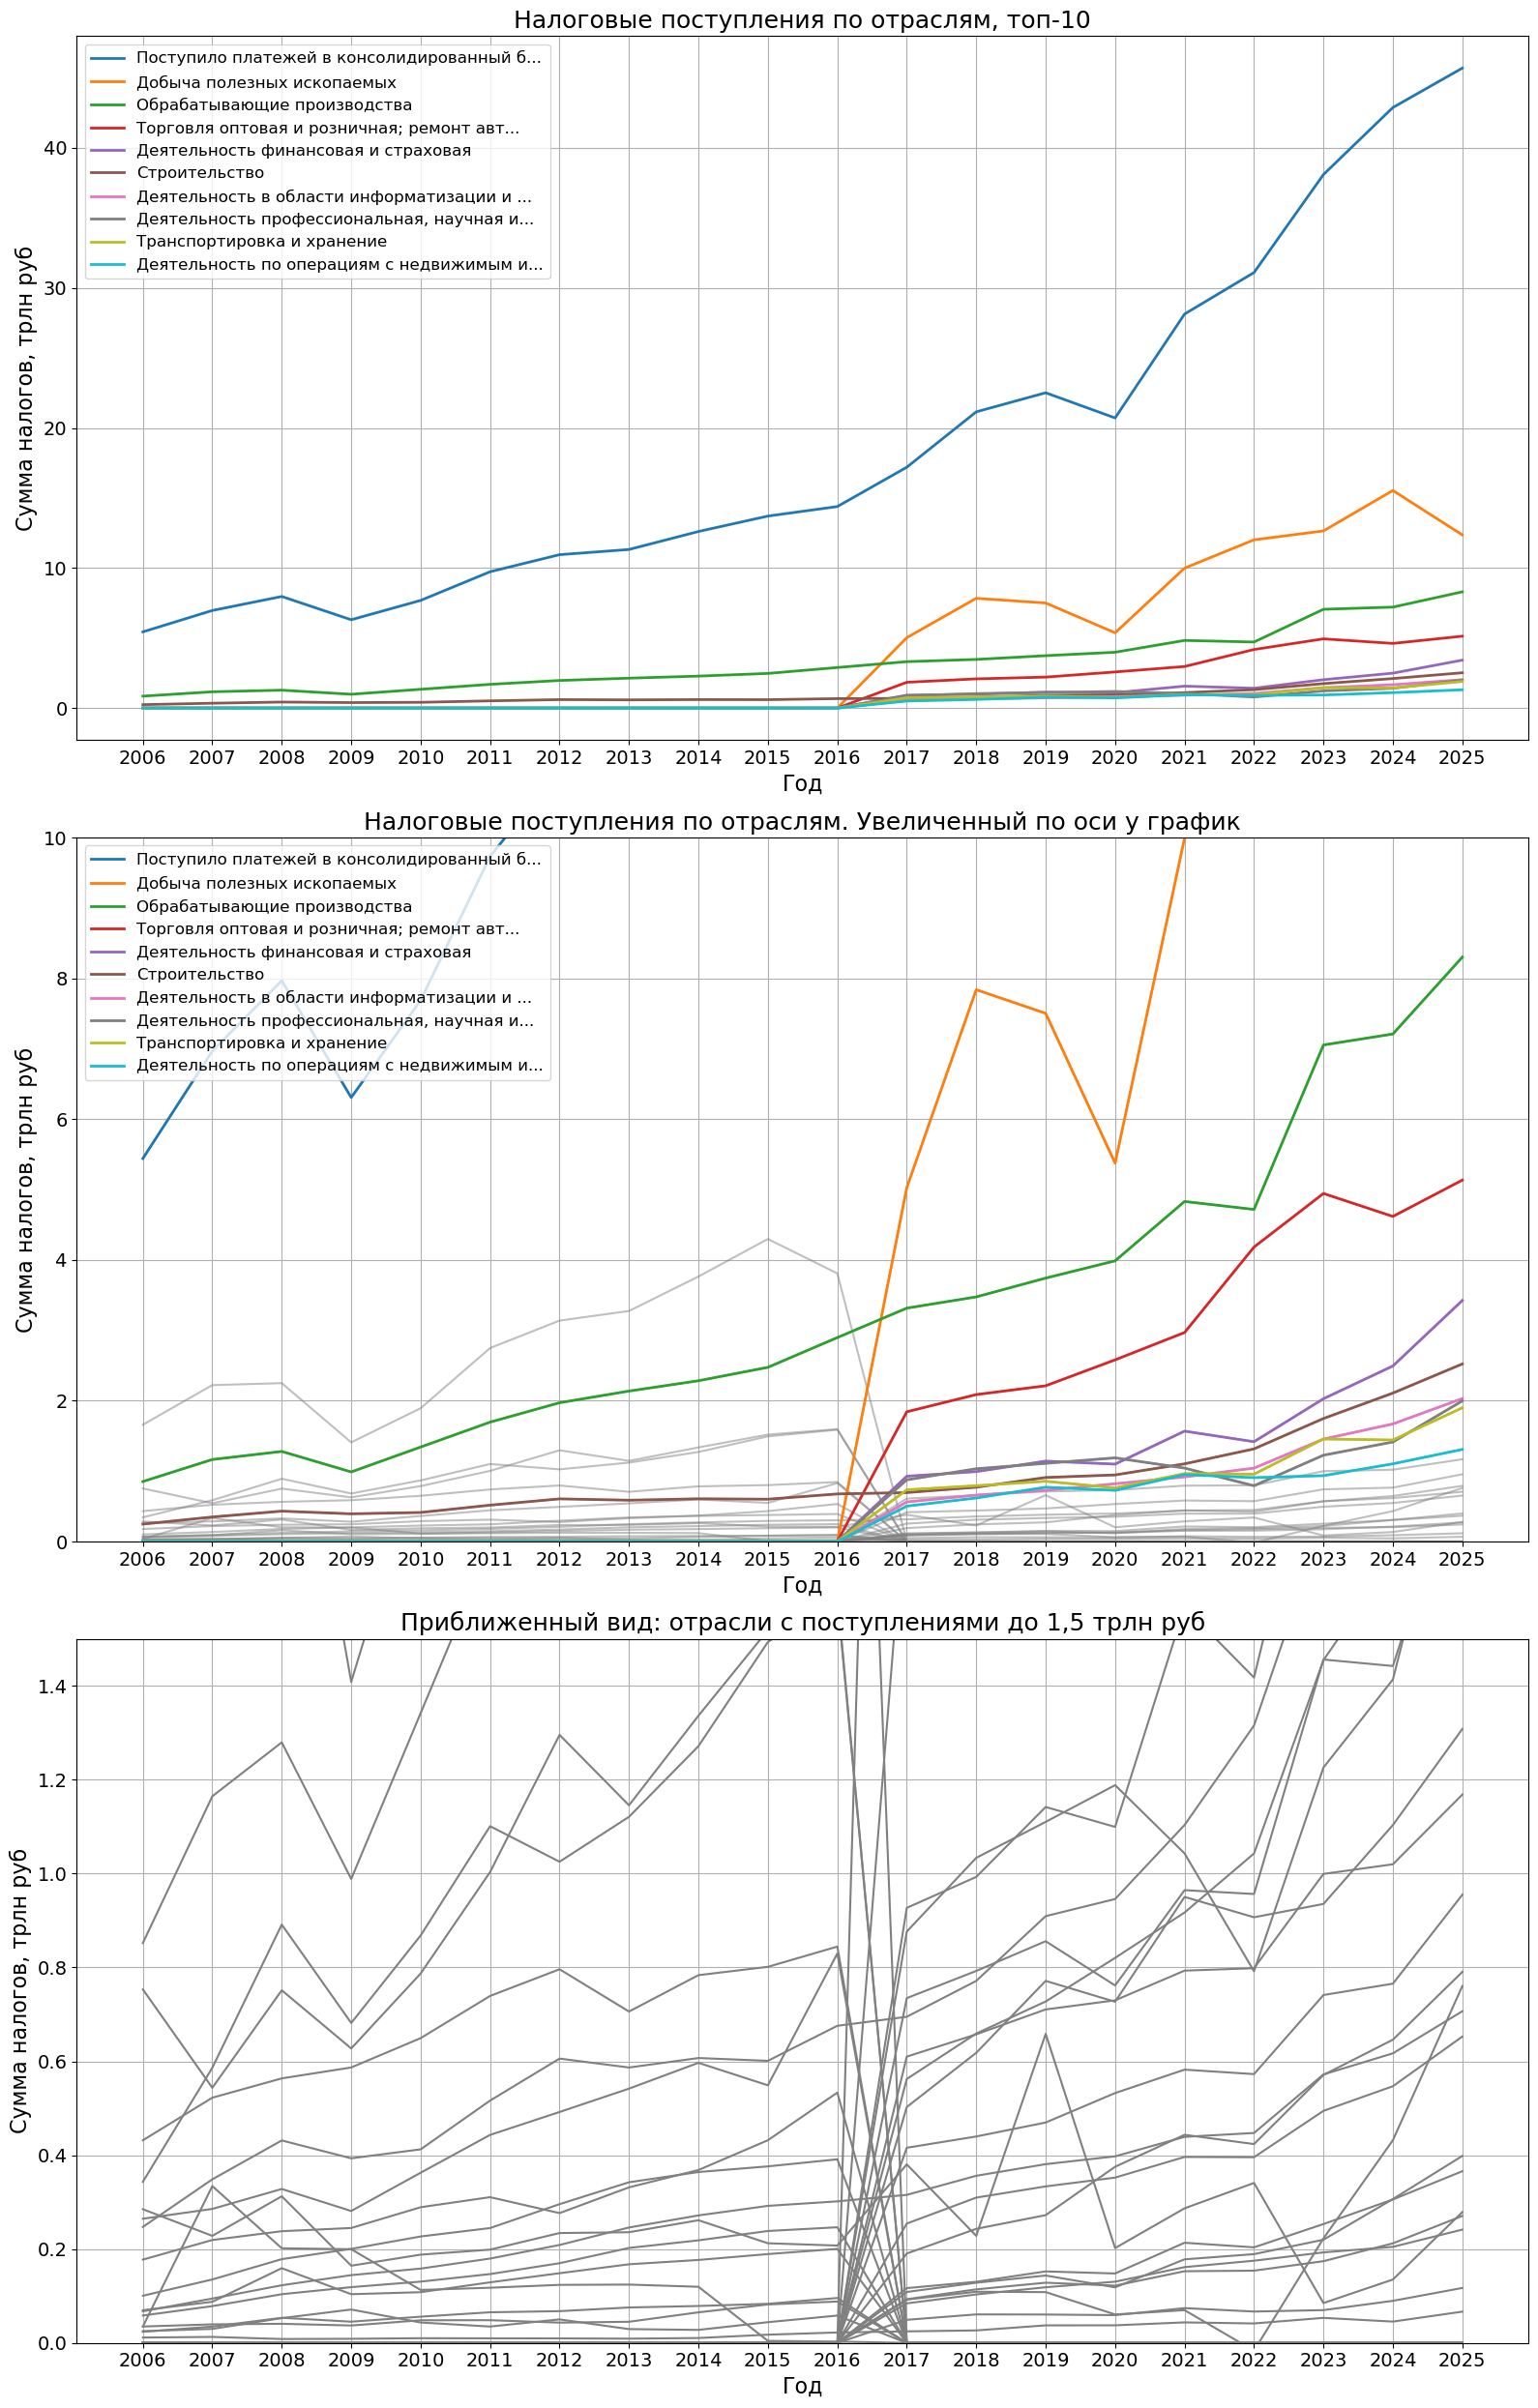

In [4]:
table_ru = table[table['Регионы'] == '643 001. РОССИЙСКАЯ ФЕДЕРАЦИЯ'].copy()
table_ru['Отрасль'] = table_ru['Справочник поступлений налоговых платежей по основным видам экономической деятельности'].str.split(' ', n=1).str[1]
#В переменной table_ru присваиваем "Справочник..." значению "Отрасль" для удобства
sectors_raw = table_ru.groupby('Отрасль')[years].sum()   
sectors_grouped = sectors_raw / 1000000000
top10_sectors = sectors_grouped[year_2025].nlargest(10)
colors = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
fig, ax = plt.subplots(3, 1, figsize=(16, 25))   #Строим три графика - мелкого, среднего и крупного масштаба

for i in range(10):
    top_name = top10_sectors.index[i]
    if len(str(top_name)) > 40:
        short_name = str(top_name)[:40] + '...'
    else:
        short_name = str(top_name)   #Для легенды нужно сократить названия - оставляем первые 40 символов
    ax[0].plot(years, sectors_grouped.loc[top_name], label=short_name, color=colors[i], lw=2)
ax[0].set_title('Налоговые поступления по отраслям, топ-10', fontsize=18)
ax[0].set_ylabel('Сумма налогов, трлн руб', fontsize=16)
ax[0].set_xlabel('Год', fontsize=16)
ax[0].legend(loc='upper left', fontsize=12)
ax[0].grid()
ax[0].tick_params(labelsize=14)   #Первый график готов

for sector_name in sectors_grouped.index:
    ax[1].plot(years, sectors_grouped.loc[sector_name], color='gray', alpha=0.5)
for i in range(10):
    top_name = top10_sectors.index[i]
    if len(str(top_name)) > 40:
        short_name = str(top_name)[:40] + '...'
    else:
        short_name = str(top_name)
    ax[1].plot(years, sectors_grouped.loc[top_name], label=short_name, color=colors[i], lw=2)
ax[1].set_title('Налоговые поступления по отраслям. Увеличенный по оси у график', fontsize=18)
ax[1].set_ylabel('Сумма налогов, трлн руб', fontsize=16)
ax[1].set_xlabel('Год', fontsize=16)
ax[1].set_ylim(0, 10)
ax[1].legend(loc='upper left', fontsize=12)
ax[1].grid()
ax[1].tick_params(labelsize=14)   #Второй график готов

for sector_name in sectors_grouped.index:
    ax[2].plot(years, sectors_grouped.loc[sector_name], color='gray', lw=1.5)
ax[2].set_ylim(0, 1.5) 
ax[2].set_title('Приближенный вид: отрасли с поступлениями до 1,5 трлн руб', fontsize=18)
ax[2].set_xlabel('Год', fontsize=16)
ax[2].set_ylabel('Сумма налогов, трлн руб', fontsize=16)
ax[2].grid()
ax[2].tick_params(labelsize=14)   #Третий график готов

plt.tight_layout()

Синяя линия сверху - это сумма всех видов. Как и ожидалось, в нашей стране наибольшую долю налогов платит **добывающая отрасль**, и этим объясняется нахождение ХМАО, ЯНАО, Красноярского края на предыдущем графике. Второе и третье место с отрывом от остальных занимают **обрабатывающие производства и торговый сектор**, и влияют на положение в топе Самарской, Свердловской, Московской областей, Пермского края и Республики Татарстан. Москва и Санкт-Петербург, являясь главными городами России, сочетают в себе и диверсифицированную экономику, и большую численность платежеспособного населения. В остальных регионах-лидерах, кроме ХМАО и ЯНАО, численность населения также играет большую роль. Таким образом, все субъекты попали в топ-10 заслуженно.

На графике есть сложное переплетение *с 2016 на 2017 год* - результат изменения названия видов экономической деятельности.

**Главные отрасли**, откуда бюджет государства получает налог: добыча полезных ископаемых, обрабатывающие производства, торговля, финансы и страхование, строительство, связь и информатизация (IT-сектор), наука, логистика, деятельность с недвижимостью.



## 3. Федеральные округа

В таблице Excel есть строки про **федеральные округа**. Их всего 8, и поэтому график, показывающий значения по ним, не будет выглядеть перегруженным и потерявшим баланс. Имеет смысл сделать его не линейным, а **столбчатым**. Для наглядности можно нарисовать две диаграммы - за более ранний и более поздний период. Выбор пал на *2010* и *2025* год - раньше первой даты данные неполные. Также пришлось *исключить Крымский ФО*, потому что выплаченные им налоги подсчитаны только в *2015* году, а затем он вообще был упразднен.

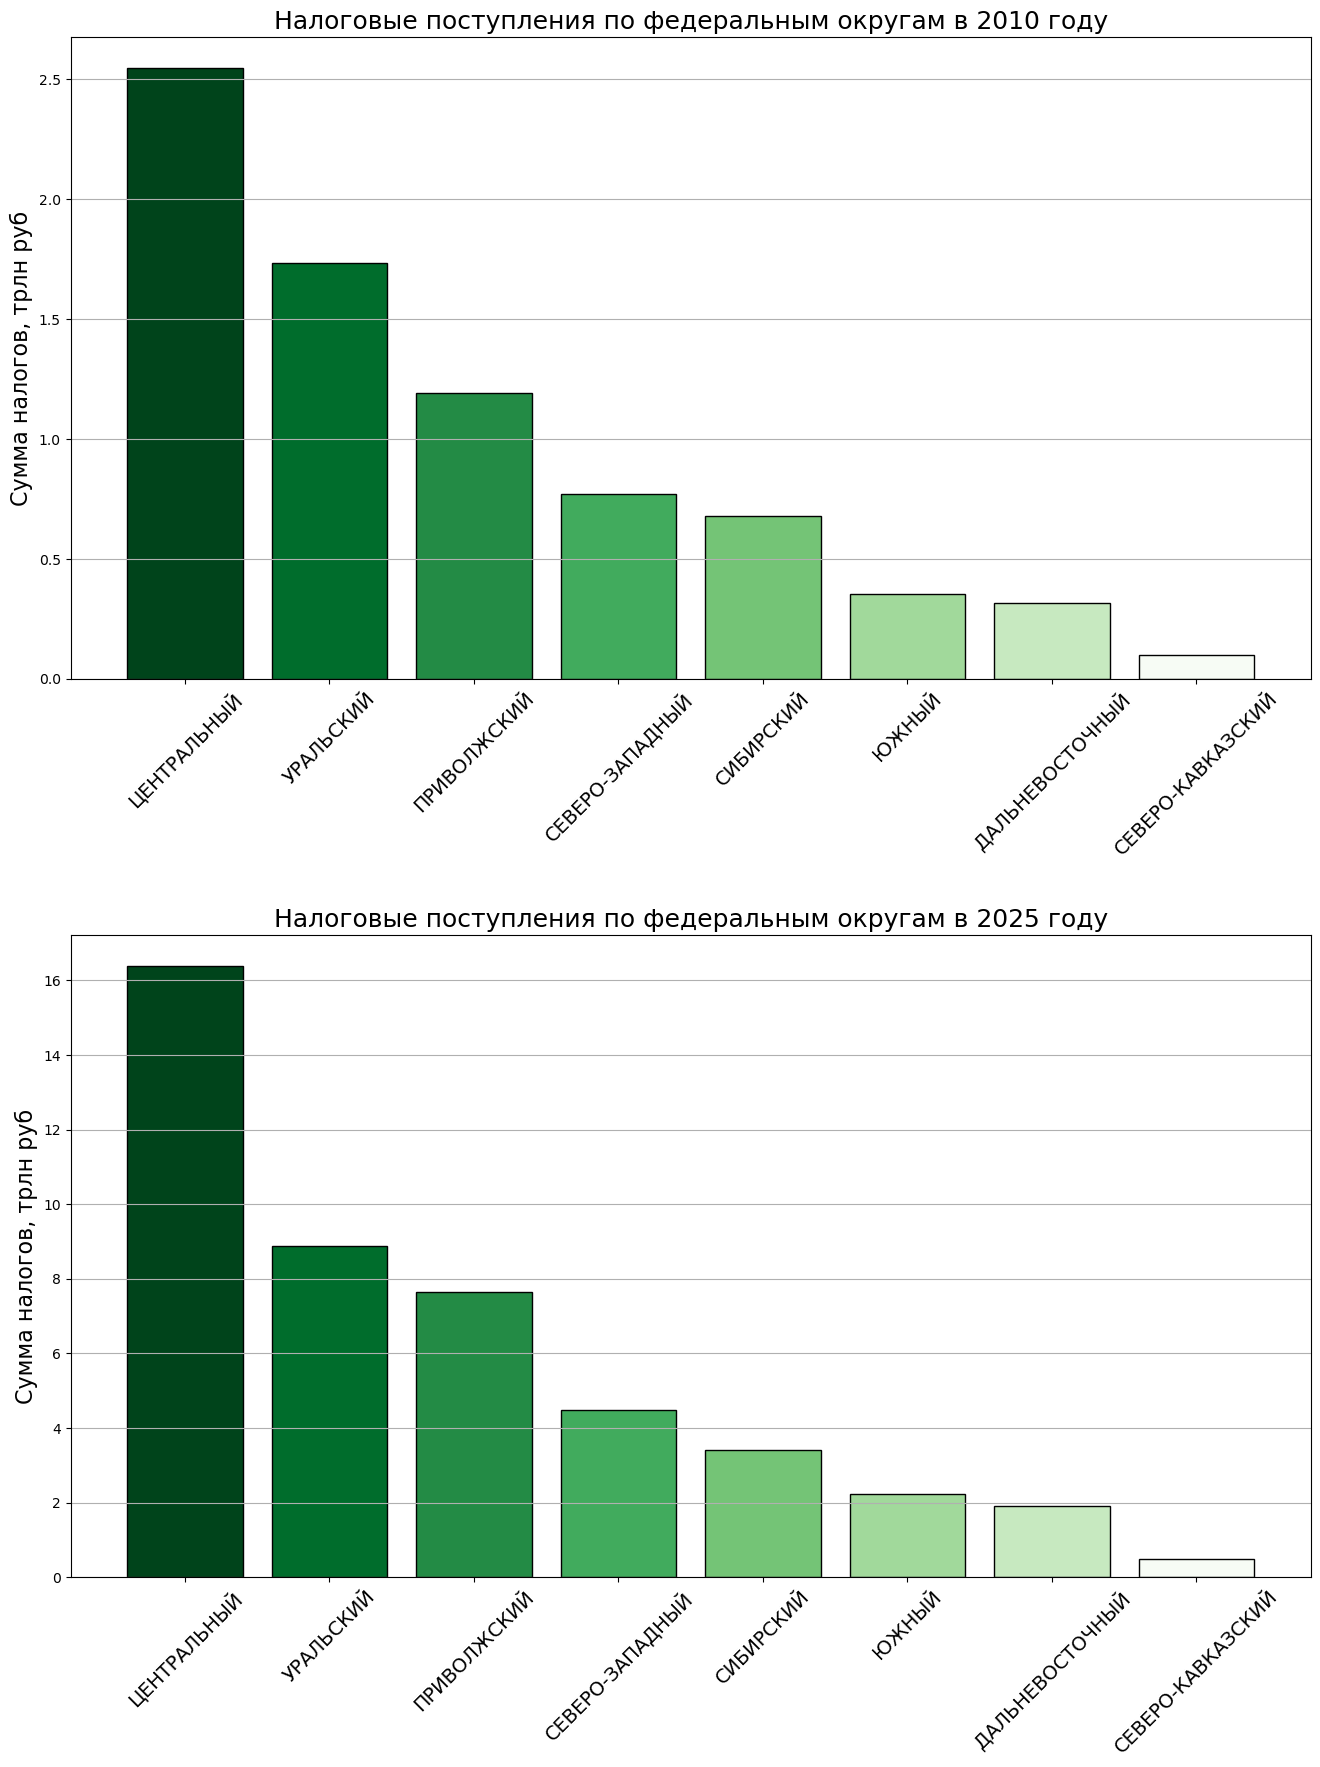

In [12]:
table_fo = table[table['Регионы'].str.contains('ФЕДЕРАЛЬНЫЙ ОКРУГ') == True].copy()   #Перебираем и добавляем в переменную table_fo строки, содержащие "ФЕДЕРАЛЬНЫЙ ОКРУГ"
table_fo = table_fo[table_fo['Справочник поступлений налоговых платежей по основным видам экономической деятельности'].str.contains('всего')]
#Перебираем виды экономической деятельности, ищем строку, включающую "всего". Там - сумма всех налогов за год
year_2010 = years[4]   #Берем начальные данные за 2010 год, потому что раньше этой даты данные неполные
def get_okrug_name(text):
    '''
    Функция принимает строку вида '030 002. ЦЕНТРАЛЬНЫЙ ФЕДЕРАЛЬНЫЙ ОКРУГ',
    разделяет ее по точке с пробелом, берет часть после точки и извлекает
    первое слово ('ЦЕНТРАЛЬНЫЙ'). Если разделитель не найден, возвращает 
    исходную строку.
    '''
    parts = text.split('. ')
    if len(parts) > 1:
        name = parts[1]
        return name.split(' ')[0]
    return text   #Функция, возвращающая нам одно слово - название федерального округа (без ФО)

table_fo['Округ'] = table_fo['Регионы'].apply(get_okrug_name)   #Применяем функцию к нашей таблице
table_fo = table_fo[table_fo['Округ'] != 'КРЫМСКИЙ']   #Исключаем данные по Крымскому ФО, потому что по нему есть только за 2015 год
fo_grouped_raw = table_fo.groupby('Округ')[years].sum()
fo_grouped = fo_grouped_raw / 1000000000
data_2010 = fo_grouped[year_2010].sort_values(ascending=False)   #Сортируем столбцы. Операция ascending=False сортирует по убыванию - слева
data_2025 = fo_grouped[year_2025].sort_values(ascending=False)   #будет самый большой столбец, справа - самый маленький.

fig, ax = plt.subplots(2, 1, figsize=(16, 20))
colors = ['#00441b', '#006d2c', '#238b45', '#41ab5d', '#74c476', '#a1d99b', '#c7e9c0', '#f7fcf5']   #Подбор цветов для столбцов

ax[0].bar(data_2010.index, data_2010.values, color=colors, edgecolor='black')   #Строим колонки, с цветами из переменной colors и с черным контуром
ax[0].set_title('Налоговые поступления по федеральным округам в 2010 году', fontsize=18)
ax[0].set_ylabel('Сумма налогов, трлн руб', fontsize=16)
ax[0].grid(axis='y')   #Проводим сетку - только горизонтальные линии
ax[0].tick_params(axis='x', rotation=45, labelsize=14)   #Поворачиваем надписи снизу на 45°

ax[1].bar(data_2025.index, data_2025.values, color=colors, edgecolor='black')
ax[1].set_title('Налоговые поступления по федеральным округам в 2025 году', fontsize=18)
ax[1].set_ylabel('Сумма налогов, трлн руб', fontsize=16)
ax[1].grid(axis='y')
ax[1].tick_params(axis='x', rotation=45, labelsize=14)

plt.subplots_adjust(hspace=0.4)   #Делаем фиксированный отступ между двумя графиками

Центральный ФО показывает абсолютное доминирование - здесь сказывается наличие сильнейшей Москвы. За 15 лет рост составил более чем в 6 раз - с 2,5 трлн до 16 трлн рублей (приблизительно). Второе место занимает Уральский ФО с ростом примерно в 5 раз (от 1,7 до 8,9 трлн рублей), его догоняет Приволжский ФО с ростом более чем в 6 раз (от 1,2 до 7,8 трлн рублей). Остальные федеральные округа стабильно занимают те же места, что и 15 лет назад, и демонстрируют рост. Наблюдается общая тенденция на усиление разрыва между федеральными округами. Увеличение выплат налогов, как отмечалось ранее, отражает экономическое развитие и рост населения.

## 4. Доли отраслей от общей суммы

Во втором разделе мы рассматривали отрасли в динамике, однако абсолютные цифры не всегда показывают полную картину. Чтобы понять, как изменилась структура налоговых поступлений страны за 20 лет, недостаточно смотреть на рубли - важно оценить **долю**, которую занимает каждая отрасль от общих налоговых поступлений.

Для этого нужно построить две круговые диаграммы для 2006 и 2025 годов. Чтобы графики оставались читаемыми, возьмем **топ-7** крупнейших отраслей, а оставшиеся мелкие категории объединим в сектор «прочие». Это позволит наглядно увидеть, какие изменения произошли в налоговой системе, и выявить сдвиги в экономике страны.

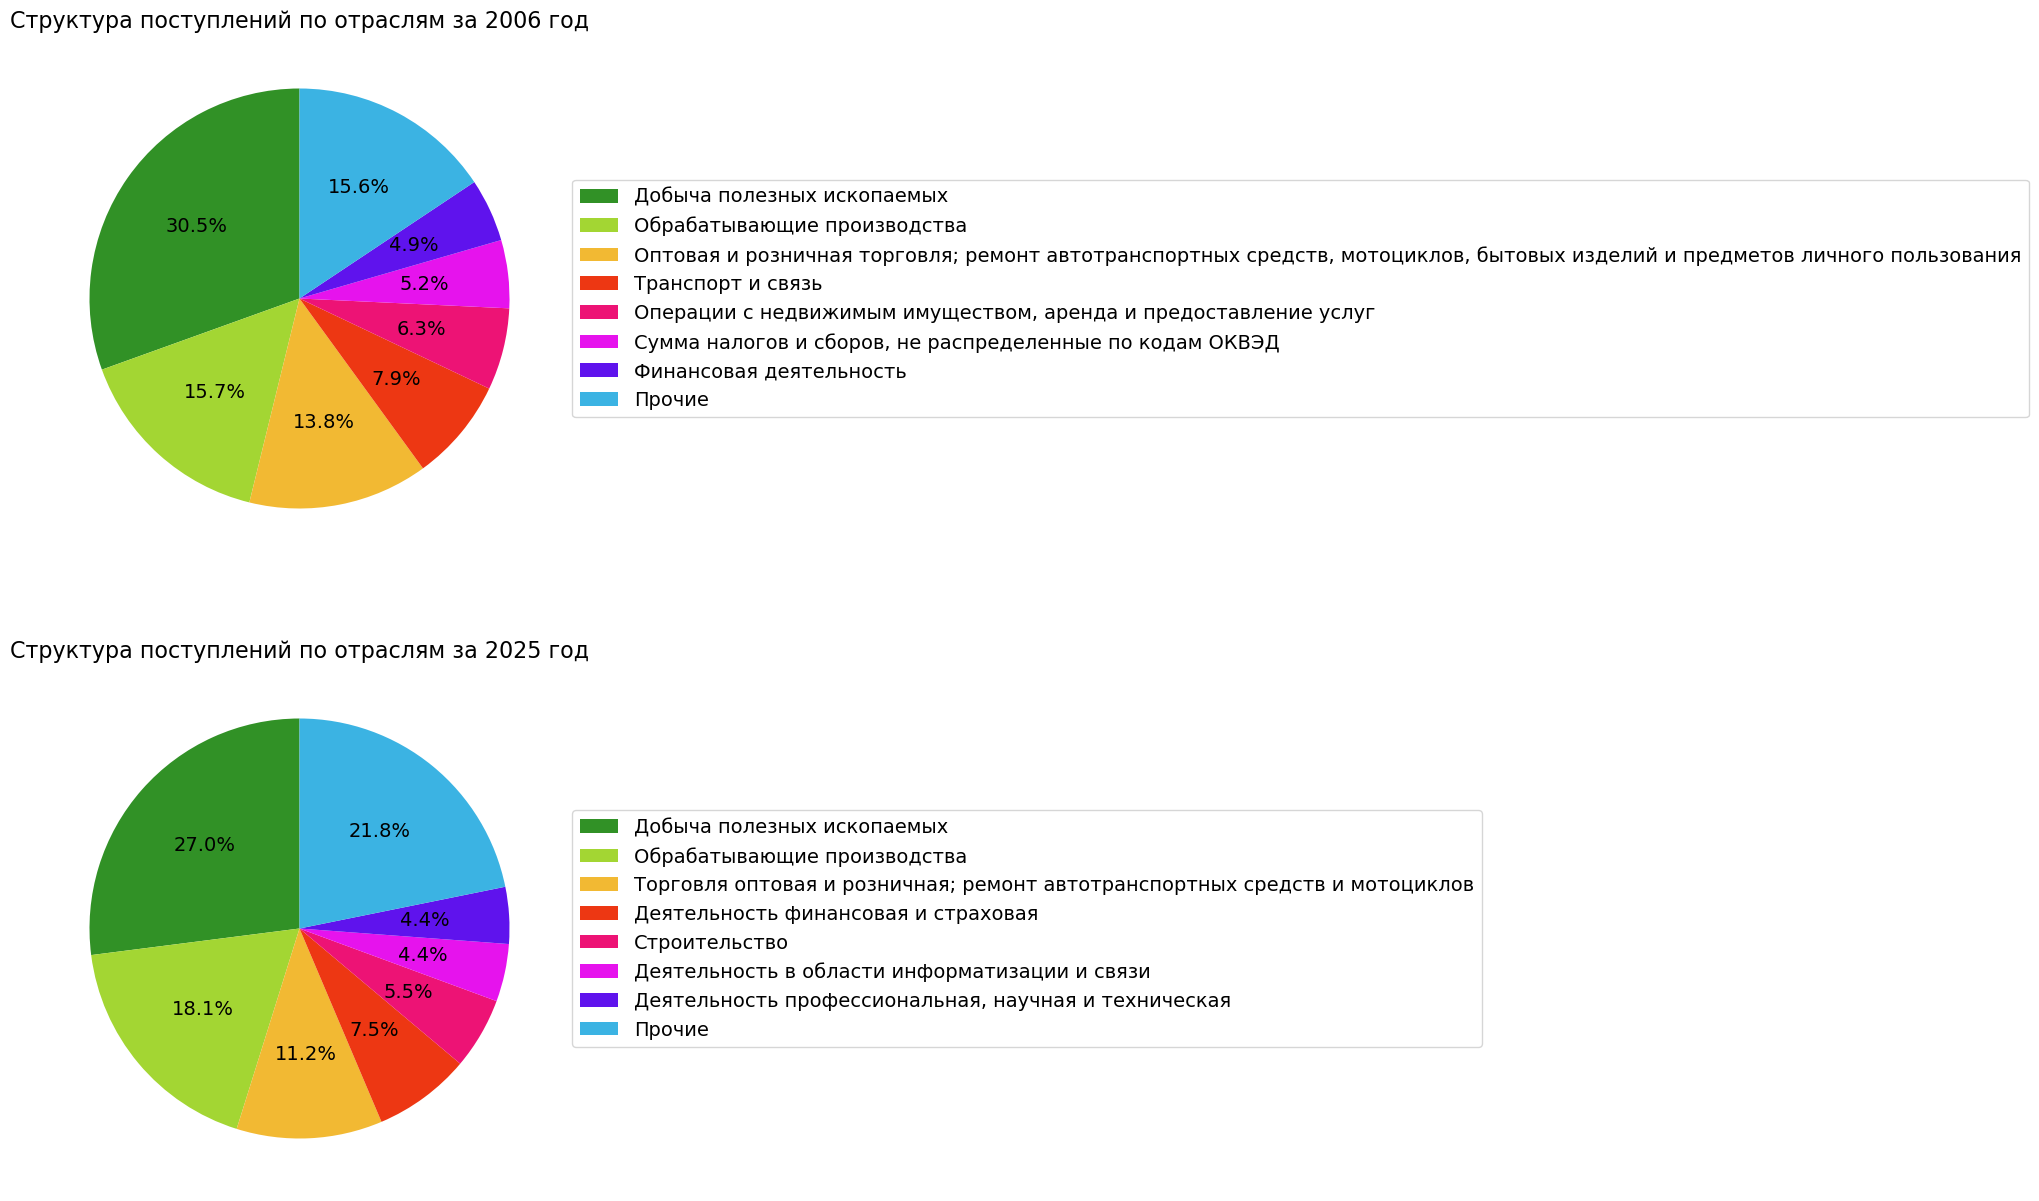

In [18]:
pie1 = sectors_grouped[year_2006]   #Вводим переменную для отраслей в 2006 году
pie2 = sectors_grouped[year_2025]   #То же, но для 2025 года
pie1 = pie1[pie1.index.str.contains('всего') == False]   #Исключаем уже подсчитанную в таблице сумму по отраслям
pie2 = pie2[pie2.index.str.contains('всего') == False]   #То же самое
def pie_data(data):
    '''
    Функция сортирует данные по убыванию, оставляя 7 крупнейших отраслей.
    Cумму значений всех остальных отраслей объединяет в категорию 'Прочие'.
    Это необходимо для того, чтобы диаграмма была читаемой
    '''
    sorted_data = data.sort_values(ascending=False)   #Сортирует в порядке убывания
    top_7 = sorted_data.head(7)   #Берет верхние 7, то есть самые большие
    others_sum = sorted_data[7:].sum()   #Суммирует оставшиеся
    result_data = top_7.copy()   #Копирует в переменную самые большие отрасли
    result_data['Прочие'] = others_sum   #Добавляем в переменную прочие отрасли
    return result_data   #Возвращает переменную

pie_2006 = pie_data(pie1)   #Применяем функцию
pie_2025 = pie_data(pie2)   #Применяем функцию
fig, ax = plt.subplots(2, 1, figsize=(12, 15))   #Два графика
colors = ['#319126', '#a3d633', '#f2b933', '#ed3713', '#ed1375', '#e613ed', '#5f13ed', '#3bb3e3']
ax[0].pie(pie_2006, autopct='%1.1f%%', colors=colors, startangle=90, textprops={'fontsize': 14})
#Задаем параметры: autopct показывает проценты до десятичных долей, startangle задает начальный угол, textprops позволяет установить размер чисел
ax[0].set_title('Структура поступлений по отраслям за 2006 год', fontsize=16)
ax[0].legend(pie_2006.index, loc='center left', bbox_to_anchor=(1, 0.5), fontsize=14)   #bbox_to_anchor выносит легенду за график, потому что без этого она налезает на пай-чарт
ax[1].pie(pie_2025, autopct='%1.1f%%', colors=colors, startangle=90, textprops={'fontsize': 14})
ax[1].set_title('Структура поступлений по отраслям за 2025 год', fontsize=16)
ax[1].legend(pie_2025.index, loc='center left', bbox_to_anchor=(1, 0.5), fontsize=14)   #Все повторяем для второго графика
plt.subplots_adjust(hspace=0.2)   #Задаем фиксированный отступ между графиками

Так, выплаты с добычи полезных ископаемых за исследуемый период уменьшились на 3,5%, но по прежнему этот сектор дает более четверти всех налоговых поступлений в бюджет. Стабильное второе место занимают обрабатывающие производства, за 20 лет их доля увеличилась на 2,4%. После них идет торговля, ее доля уменьшилась на 2,6%. Сектор финансов стал платить больше налогов - с седьмого места в 2006 он поднялся до четвертого в 2025. Также в 2025 году в топе появились новые отрасли: строительство, информатизация и связь, профессиональная, научная и техническая деятельность, а транспорт и операции с недвижимым имуществом исчезли. Сектор "Прочие" увеличился на 6,2% - это свидетельствует о совокупном росте выплат с остальных, более мелких отраслей.

## Выводы

В начале этого исследования было сказано об очередном *повышении налогов*. Это исследование показало, что они *продолжали расти* последние 20 лет. Налоговая система России демонстрирует устойчивый рост, перегнавший инфляцию, однако этот рост *крайне неравномерен* как в географическом, так и в отраслевом разрезе. А так как налоги - это **"зеркало" экономики**, то можно сделать и сравнительные выводы о экономической ситуации в России. *Сырьевая зависимость* в России все еще остается сильной. Усиливается разрыв между регионами, федеральными округами. Столица концентрирует в себе все больше и больше денег.
Исходя из этого можно сказать, что экономика России остро нуждается в *диверсификации*, а отстающие регионы - в помощи в развитии.

## Источники

1. Национальный центр социально-экономических данных. Поступление налогов и сборов в бюджетную систему Российской Федерации по основным видам экономической деятельности, рубли, Россия (2006 - 2026) ([ссылка](https://search.nsedc.ru/?q=налоговые+поступления&sources=Репозиторий+НЦСЭД))
2. Список упраздненных и переименованных регионов Российской Федерации ([ссылка](https://ru.wikipedia.org/wiki/Список_упразднённых_и_переименованных_регионов_Российской_Федерации))
3. Калькулятор инфляции ([ссылка](https://calcus.ru/inflyaciya?input=bW9udGgxPTEmeWVhcjE9MjAwNiZtb250aDI9MTImeWVhcjI9MjAyNQ==))
4. Валовый региональный продукт России. Регионы - статистика с 1998 по 2024 годы ([ссылка](https://statbase.ru/datasets/national-statistics-of-russia/economics/gross-domestic-product-by-region-national-stat/?syear=2024&frmreq=0&sproc=sum&filter=&sort=))